In [1]:
import pandas as pd

df = pd.read_csv("CodeAlpha_EDA_Ecommerce_Dataset.csv")

df.head()

,OrderID,OrderDate,CustomerID,CustomerName,ProductName,Category,City,Region,Quantity,UnitPrice,DiscountPct,Sales,PaymentMethod,OrderStatus
0,ORD0001,2025-02-01,C070,Customer_021,Laptop,Electronics,Jaipur,North,4,58944.58,0.10,212200.49,UPI,Completed
1,ORD0002,2025-02-16,C084,Customer_046,Water Bottle,Accessories,Chennai,South,4,475.75,0.10,1712.70,Debit Card,Completed
2,ORD0003,2025-07-19,C045,Customer_046,Smartphone,Electronics,Ahmedabad,West,4,23420.15,0.15,79628.51,Credit Card,Completed
3,ORD0004,2025-08-19,C017,Customer_076,Notebook,Stationery,Ahmedabad,West,1,85.24,0.05,80.98,Cash,Completed
4,ORD0005,2025-10-05,C020,Customer_037,Laptop,Electronics,Ahmedabad,West,3,58062.22,0.20,139349.33,Debit Card,Completed


In [2]:
df.shape

(502, 14)

In [3]:
df.columns

Index(['OrderID', 'OrderDate', 'CustomerID', 'CustomerName', 'ProductName',
       'Category', 'City', 'Region', 'Quantity', 'UnitPrice', 'DiscountPct',
       'Sales', 'PaymentMethod', 'OrderStatus'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 502 entries, 0 to 501
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   OrderID        502 non-null    str    
 1   OrderDate      502 non-null    str    
 2   CustomerID     502 non-null    str    
 3   CustomerName   502 non-null    str    
 4   ProductName    502 non-null    str    
 5   Category       502 non-null    str    
 6   City           494 non-null    str    
 7   Region         502 non-null    str    
 8   Quantity       502 non-null    int64  
 9   UnitPrice      502 non-null    float64
 10  DiscountPct    497 non-null    float64
 11  Sales          502 non-null    float64
 12  PaymentMethod  502 non-null    str    
 13  OrderStatus    502 non-null    str    
dtypes: float64(3), int64(1), str(10)
memory usage: 94.2 KB


In [5]:
df.describe()

,Quantity,UnitPrice,DiscountPct,Sales
count,502.000000,502.000000,497.000000,502.000000
mean,2.910359,10374.286195,0.100805,27530.181833
std,1.424736,17206.682469,0.070991,53343.616499
min,1.000000,72.060000,0.000000,65.990000
25%,2.000000,444.362500,0.050000,652.870000
50%,3.000000,2251.500000,0.100000,4654.575000
75%,4.000000,9046.837500,0.150000,22803.102500
max,5.000000,60436.960000,0.200000,293942.450000


In [6]:
df.isnull().sum()

OrderID          0
OrderDate        0
CustomerID       0
CustomerName     0
ProductName      0
Category         0
City             8
Region           0
Quantity         0
UnitPrice        0
DiscountPct      5
Sales            0
PaymentMethod    0
OrderStatus      0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(2)

In [8]:
# How many orders are Completed, Cancelled and Returned?

status_analysis = df["OrderStatus"].value_counts()
status_analysis


OrderStatus
Completed    312
Returned     108
Cancelled     82
Name: count, dtype: int64

In [9]:
# Which product generates the highest sales?

product_sales = df.groupby("ProductName")["Sales"].sum()

product_sales = product_sales.sort_values(ascending=False)

product_sales

ProductName
Laptop          8679825.76
Smartphone      2587931.86
Desk            1129450.89
Office Chair     724453.52
Headphones       325447.50
Backpack         206324.37
Mouse             76385.80
Water Bottle      61317.64
Pen Pack          19228.31
Notebook           9785.63
Name: Sales, dtype: float64

In [10]:
# Which city generates the highest sales

city_sales = df.groupby("City")["Sales"].sum()

city_sales = city_sales.sort_values(ascending=False)

city_sales

City
Bengaluru    2282179.51
Hyderabad    2201340.71
Ahmedabad    2043847.74
Chennai      1916396.48
Mumbai       1679382.24
Jaipur       1642772.49
Pune         1057479.96
Delhi         907785.96
Name: Sales, dtype: float64

In [11]:
# Which category performs best?

category_sales = df.groupby("Category")["Sales"].sum()

category_sales = category_sales.sort_values(ascending=False)

category_sales

Category
Electronics    11517505.26
Furniture       1819820.05
Accessories      263665.36
ELECTRONICS      152085.66
FURNITURE         34084.36
Stationery        28674.28
ACCESSORIES        3976.65
STATIONERY          339.66
Name: Sales, dtype: float64

In [12]:
# Which payment method is most popular?

payment_analysis = df["PaymentMethod"].value_counts()

payment_analysis =payment_analysis.sort_values(ascending=False)

payment_analysis

PaymentMethod
Credit Card    111
UPI            110
Debit Card     110
Cash            91
Net Banking     80
Name: count, dtype: int64

In [13]:
# Which month generates the highest sales?

df["OrderDate"] = pd.to_datetime(df["OrderDate"])

monthly_sales = df.groupby(
    df["OrderDate"].dt.month_name()
)["Sales"].sum()

monthly_sales

OrderDate
April        1190597.40
August        704792.47
December      686850.71
February     1041647.27
January      1128235.65
July          873787.58
June          896804.12
March        1602942.95
May          1432724.20
November      907481.50
October      2074194.55
September    1280092.88
Name: Sales, dtype: float64

In [14]:
    # What is the average sales value per order?
average_sales = df["Sales"].mean()

print("Average Order Value:", average_sales)

Average Order Value: 27530.18183266932


In [15]:
# Which are the top 5 products by sales?

top_products = df.groupby("ProductName")["Sales"].sum()

top_products.sort_values(
    ascending=False
).head(5)


ProductName
Laptop          8679825.76
Smartphone      2587931.86
Desk            1129450.89
Office Chair     724453.52
Headphones       325447.50
Name: Sales, dtype: float64

In [16]:
#Which region generates the highest sales?

region_sales = df.groupby("Region")["Sales"].sum()

region_sales.sort_values(ascending=False)

Region
South    6459357.03
West     4792397.95
North    2568396.30
Name: Sales, dtype: float64

In [17]:
# How many total units were sold? 

total_quantity = df["Quantity"].sum()

print("Total Units Sold:", total_quantity)

Total Units Sold: 1461


In [18]:
# Which 10 customers generate the highest sales?

customer_sales = df.groupby("CustomerName")["Sales"].sum()

customer_sales.sort_values(
    ascending=False
).head(10)

CustomerName
Customer_099    760481.38
Customer_015    469220.69
Customer_042    433504.26
Customer_059    390119.26
Customer_084    389460.60
Customer_022    340276.09
Customer_083    339308.74
Customer_091    332443.25
Customer_010    322576.81
Customer_075    309901.77
Name: Sales, dtype: float64

In [19]:
# How much sales value belongs to each order status?

status_sales = df.groupby("OrderStatus")["Sales"].sum()

status_sales

OrderStatus
Cancelled    2209407.96
Completed    7877287.53
Returned     3733455.79
Name: Sales, dtype: float64

In [20]:
# Monthly Sales Trend
monthly_trend = df.groupby(
    df["OrderDate"].dt.to_period("M")
)["Sales"].sum()

monthly_trend

OrderDate
2025-01    1128235.65
2025-02    1041647.27
2025-03    1602942.95
2025-04    1190597.40
2025-05    1432724.20
2025-06     896804.12
2025-07     873787.58
2025-08     704792.47
2025-09    1280092.88
2025-10    2074194.55
2025-11     907481.50
2025-12     686850.71
Freq: M, Name: Sales, dtype: float64

In [21]:
# hightes monthly sales

print("Highest Sales Month:")
print(monthly_trend.idxmax(), monthly_trend.max())

print("Lowest Sales Month:")
print(monthly_trend.idxmin(), monthly_trend.min())

Highest Sales Month:
2025-10 2074194.55
Lowest Sales Month:
2025-12 686850.71


In [22]:
# Sales Outlier Detection

Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Sales"] < lower_limit) |
    (df["Sales"] > upper_limit)
]

print("Number of Outliers:", len(outliers))

Number of Outliers: 71


In [23]:
from scipy.stats import f_oneway

west = df[df["Region"] == "West"]["Sales"].dropna()
north = df[df["Region"] == "North"]["Sales"].dropna()
south = df[df["Region"] == "South"]["Sales"].dropna()

f_stat, p_value = f_oneway(west, north, south)

print("F-Statistic:", f_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject H0: Significant difference exists.")
else:
    print("Fail to reject H0: No significant difference found.")

F-Statistic: 1.6977565477733711
P-Value: 0.18414969150352822
Fail to reject H0: No significant difference found.


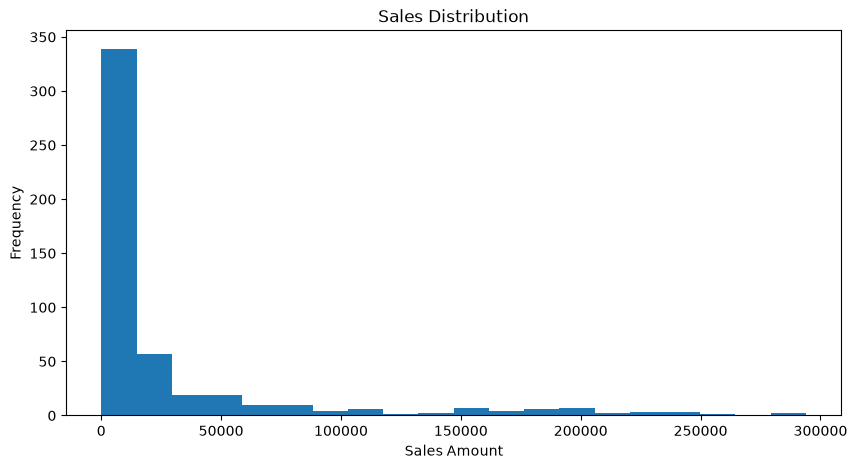

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df["Sales"], bins=20)

plt.title("Sales Distribution")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")

plt.show()


In [39]:
correlation = df[
    ["Quantity", "UnitPrice", "DiscountPct", "Sales"]
].corr()

correlation

,Quantity,UnitPrice,DiscountPct,Sales
Quantity,1.000000,0.007651,-0.003244,0.248967
UnitPrice,0.007651,1.000000,-0.057906,0.876178
DiscountPct,-0.003244,-0.057906,1.000000,-0.089426
Sales,0.248967,0.876178,-0.089426,1.000000


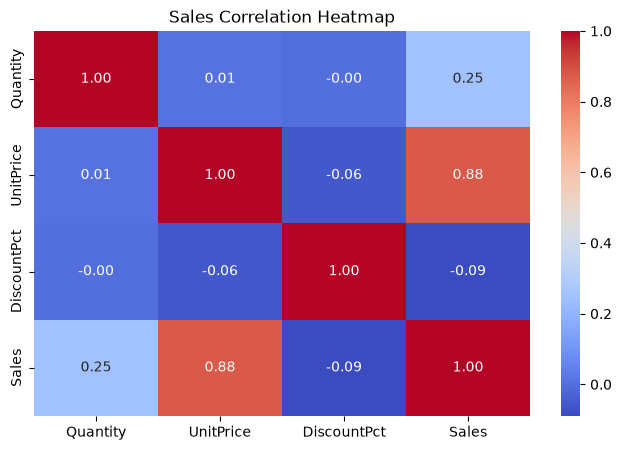

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Sales Correlation Heatmap")
plt.show()

In [41]:
missing_data = df[df.isnull().any(axis=1)]

missing_data

,OrderID,OrderDate,CustomerID,CustomerName,ProductName,Category,City,Region,Quantity,UnitPrice,DiscountPct,Sales,PaymentMethod,OrderStatus
17,ORD0018,2025-05-13,C096,Customer_009,Office Chair,Furniture,NaN,West,2,6669.37,0.15,11337.93,Credit Card,Completed
40,ORD0041,2025-04-25,C096,Customer_053,Water Bottle,Accessories,NaN,North,1,464.66,0.10,418.19,Credit Card,Returned
54,ORD0055,2025-08-13,C078,Customer_074,Office Chair,Furniture,NaN,North,3,6685.23,0.15,17047.34,UPI,Returned
111,ORD0112,2025-12-26,C016,Customer_029,Notebook,Stationery,NaN,West,4,87.52,0.00,350.08,Net Banking,Cancelled
261,ORD0262,2025-12-08,C088,Customer_098,Water Bottle,Accessories,Jaipur,North,2,451.42,NaN,767.41,UPI,Completed
262,ORD0263,2025-02-24,C020,Customer_015,Notebook,Stationery,Pune,West,2,73.01,NaN,146.02,Debit Card,Completed
264,ORD0265,2025-02-10,C010,Customer_048,Pen Pack,Stationery,NaN,North,4,116.35,0.20,372.32,Credit Card,Completed
282,ORD0283,2025-11-25,C024,Customer_054,Laptop,Electronics,Bengaluru,South,4,53562.00,NaN,203535.60,Cash,Completed
335,ORD0336,2025-08-17,C020,Customer_033,Smartphone,Electronics,Pune,West,5,20536.41,NaN,92413.85,Credit Card,Cancelled
346,ORD0347,2025-09-04,C045,Customer_039,Smartphone,Electronics,Mumbai,West,3,21756.63,NaN,55479.41,UPI,Completed


In [105]:
duplicate_data = df[df.duplicated(keep=False)]

duplicate_data

,OrderID,OrderDate,CustomerID,CustomerName,ProductName,Category,City,Region,Quantity,UnitPrice,DiscountPct,Sales,PaymentMethod,OrderStatus
12,ORD0013,2025-05-07,C044,Customer_099,Laptop,Electronics,Hyderabad,South,4,49839.00,0.05,189388.20,Credit Card,Completed
45,ORD0046,2025-08-26,C097,Customer_087,Desk,Furniture,Pune,West,2,8866.59,0.00,17733.18,Credit Card,Completed
500,ORD0013,2025-05-07,C044,Customer_099,Laptop,Electronics,Hyderabad,South,4,49839.00,0.05,189388.20,Credit Card,Completed
501,ORD0046,2025-08-26,C097,Customer_087,Desk,Furniture,Pune,West,2,8866.59,0.00,17733.18,Credit Card,Completed


In [106]:
df_clean = df.copy()

print("Original Rows:", len(df))
print("Working Copy Rows:", len(df_clean))

Original Rows: 502
Working Copy Rows: 502


In [107]:
df_clean[df_clean["City"].isnull()]

,OrderID,OrderDate,CustomerID,CustomerName,ProductName,Category,City,Region,Quantity,UnitPrice,DiscountPct,Sales,PaymentMethod,OrderStatus
17,ORD0018,2025-05-13,C096,Customer_009,Office Chair,Furniture,NaN,West,2,6669.37,0.15,11337.93,Credit Card,Completed
40,ORD0041,2025-04-25,C096,Customer_053,Water Bottle,Accessories,NaN,North,1,464.66,0.10,418.19,Credit Card,Returned
54,ORD0055,2025-08-13,C078,Customer_074,Office Chair,Furniture,NaN,North,3,6685.23,0.15,17047.34,UPI,Returned
111,ORD0112,2025-12-26,C016,Customer_029,Notebook,Stationery,NaN,West,4,87.52,0.00,350.08,Net Banking,Cancelled
264,ORD0265,2025-02-10,C010,Customer_048,Pen Pack,Stationery,NaN,North,4,116.35,0.20,372.32,Credit Card,Completed
359,ORD0360,2025-12-11,C053,Customer_074,Smartphone,Electronics,NaN,South,2,21841.26,0.10,39314.27,UPI,Completed
417,ORD0418,2025-09-23,C062,Customer_005,Office Chair,Furniture,NaN,South,2,5901.38,0.00,11802.76,Net Banking,Completed
466,ORD0467,2025-06-23,C005,Customer_073,Headphones,Electronics,NaN,South,4,2448.03,0.15,8323.30,UPI,Completed


In [108]:
df_clean["City"] = df_clean["City"].fillna("Unknown")

In [109]:
print("Working Data Rows:", len(df_clean))

print("Missing City Values:",
      df_clean["City"].isnull().sum())

Working Data Rows: 502
Missing City Values: 0


In [110]:
df_clean["DiscountPct"].median()

np.float64(0.1)

In [111]:
median_discount = df_clean["DiscountPct"].median()

df_clean["DiscountPct"] = df_clean["DiscountPct"].fillna(median_discount)

print("Missing Discounts:", df_clean["DiscountPct"].isnull().sum())

Missing Discounts: 0


In [81]:
df_clean.isnull().sum()

OrderID          0
OrderDate        0
CustomerID       0
CustomerName     0
ProductName      0
Category         0
City             0
Region           0
Quantity         0
UnitPrice        0
DiscountPct      0
Sales            0
PaymentMethod    0
OrderStatus      0
dtype: int64

In [112]:
df_clean.duplicated().sum()

np.int64(2)

In [113]:
df_clean = df_clean.drop_duplicates()

print("Remaining Duplicates:", df_clean.duplicated().sum())
print("Final Rows:", len(df_clean))

Remaining Duplicates: 0
Final Rows: 500


In [114]:
print("Final Rows:", df_clean.shape[0])
print("Final Columns:", df_clean.shape[1])

Final Rows: 500
Final Columns: 14


In [115]:
df_clean["Category"].value_counts()

Category
Electronics    192
Accessories    106
Stationery     102
Furniture       93
ELECTRONICS      3
ACCESSORIES      2
FURNITURE        1
STATIONERY       1
Name: count, dtype: int64

In [116]:
df_clean["Category"] = df_clean["Category"].str.strip().str.title()

In [117]:
df_clean["Category"].value_counts()

Category
Electronics    195
Accessories    108
Stationery     103
Furniture       94
Name: count, dtype: int64

In [122]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

display(df_clean)

,OrderID,OrderDate,CustomerID,CustomerName,ProductName,Category,City,Region,Quantity,UnitPrice,DiscountPct,Sales,PaymentMethod,OrderStatus
0,ORD0001,2025-02-01,C070,Customer_021,Laptop,Electronics,Jaipur,North,4,58944.58,0.10,212200.49,UPI,Completed
1,ORD0002,2025-02-16,C084,Customer_046,Water Bottle,Accessories,Chennai,South,4,475.75,0.10,1712.70,Debit Card,Completed
2,ORD0003,2025-07-19,C045,Customer_046,Smartphone,Electronics,Ahmedabad,West,4,23420.15,0.15,79628.51,Credit Card,Completed
3,ORD0004,2025-08-19,C017,Customer_076,Notebook,Stationery,Ahmedabad,West,1,85.24,0.05,80.98,Cash,Completed
4,ORD0005,2025-10-05,C020,Customer_037,Laptop,Electronics,Ahmedabad,West,3,58062.22,0.20,139349.33,Debit Card,Completed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,ORD0496,2025-09-28,C085,Customer_079,Office Chair,Furniture,Chennai,South,3,6068.32,0.05,17294.71,Credit Card,Completed
496,ORD0497,2025-09-16,C030,Customer_020,Smartphone,Electronics,Bengaluru,South,3,19811.91,0.20,47548.58,Debit Card,Completed
497,ORD0498,2025-03-08,C006,Customer_053,Office Chair,Furniture,Hyderabad,South,2,6448.05,0.15,10961.68,Credit Card,Cancelled
498,ORD0499,2025-07-14,C018,Customer_022,Laptop,Electronics,Hyderabad,South,5,58788.49,0.00,293942.45,Cash,Returned


In [126]:
print("Invalid Quantity:",
      (df_clean["Quantity"] <= 0).sum())

print("Invalid Unit Price:",
      (df_clean["UnitPrice"] <= 0).sum())

print("Invalid Discount:",
      ((df_clean["DiscountPct"] < 0) |
       (df_clean["DiscountPct"] > 1)).sum())

Invalid Quantity: 0
Invalid Unit Price: 0
Invalid Discount: 0


In [125]:
# datavaldatio
# Quantity Validation
df_clean[df_clean["Quantity"] <= 0]

,OrderID,OrderDate,CustomerID,CustomerName,ProductName,Category,City,Region,Quantity,UnitPrice,DiscountPct,Sales,PaymentMethod,OrderStatus


In [119]:
# Unit Price Validation
df_clean[df_clean["UnitPrice"] <= 0]

,OrderID,OrderDate,CustomerID,CustomerName,ProductName,Category,City,Region,Quantity,UnitPrice,DiscountPct,Sales,PaymentMethod,OrderStatus


In [120]:
# Discount Validation
df_clean[
    (df_clean["DiscountPct"] < 0) |
    (df_clean["DiscountPct"] > 1)
]

,OrderID,OrderDate,CustomerID,CustomerName,ProductName,Category,City,Region,Quantity,UnitPrice,DiscountPct,Sales,PaymentMethod,OrderStatus


In [127]:
Q1 = df_clean["Sales"].quantile(0.25)
Q3 = df_clean["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["Sales"] < lower_limit) |
    (df_clean["Sales"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Total Outliers:", len(outliers))

Lower Limit: -32518.786250000005
Upper Limit: 55925.683750000004
Total Outliers: 70


In [128]:
outliers[[
    "OrderID",
    "ProductName",
    "Category",
    "Quantity",
    "UnitPrice",
    "DiscountPct",
    "Sales",
    "Region"
]]

,OrderID,ProductName,Category,Quantity,UnitPrice,DiscountPct,Sales,Region
0,ORD0001,Laptop,Electronics,4,58944.58,0.10,212200.49,North
2,ORD0003,Smartphone,Electronics,4,23420.15,0.15,79628.51,West
4,ORD0005,Laptop,Electronics,3,58062.22,0.20,139349.33,West
12,ORD0013,Laptop,Electronics,4,49839.00,0.05,189388.20,South
20,ORD0021,Smartphone,Electronics,4,21146.21,0.05,80355.60,South
22,ORD0023,Laptop,Electronics,4,54073.88,0.00,216295.52,South
26,ORD0027,Smartphone,Electronics,3,20974.69,0.10,56631.66,South
35,ORD0036,Smartphone,Electronics,5,20474.45,0.15,87016.41,West
36,ORD0037,Laptop,Electronics,2,58051.45,0.05,110297.75,West
47,ORD0048,Laptop,Electronics,3,51107.91,0.00,153323.73,South


In [129]:
print("Total Orders:", len(df_clean))
print("Total Outliers:", len(outliers))

print("\nOutliers by Category:")
print(outliers["Category"].value_counts())

print("\nAverage Sales of Outliers:")
print(outliers["Sales"].mean())

print("\nMaximum Sales:")
print(outliers["Sales"].max())

Total Orders: 500
Total Outliers: 70

Outliers by Category:
Category
Electronics    70
Name: count, dtype: int64

Average Sales of Outliers:
140635.53

Maximum Sales:
293942.45


In [130]:
print("========== EDA FINAL SUMMARY ==========")

print("Total Records:", len(df_clean))

print("Total Columns:", len(df_clean.columns))

print("Missing Values:",
      df_clean.isnull().sum().sum())

print("Duplicate Records:",
      df_clean.duplicated().sum())

print("Total Outliers:", len(outliers))

print("Total Sales:", round(df_clean["Sales"].sum(), 2))

print("Average Sales:", round(df_clean["Sales"].mean(), 2))

print("Total Quantity:", df_clean["Quantity"].sum())

print("Top Selling Product:")
print(df_clean.groupby("ProductName")["Sales"]
      .sum().sort_values(ascending=False).head(1))

print("Top Sales Category:")
print(df_clean.groupby("Category")["Sales"]
      .sum().sort_values(ascending=False).head(1))

print("=======================================")

========== EDA FINAL SUMMARY ==========
Total Records: 500
Total Columns: 14
Missing Values: 0
Duplicate Records: 0
Total Outliers: 70
Total Sales: 13613029.9
Average Sales: 27226.06
Total Quantity: 1455
Top Selling Product:
ProductName
Laptop    8490437.56
Name: Sales, dtype: float64
Top Sales Category:
Category
Electronics    11480202.72
Name: Sales, dtype: float64


In [135]:
# Business Insights

product_sales = df_clean.groupby("ProductName")["Sales"].sum()
product_sales = product_sales.sort_values(ascending=False)

print("Product-wise Sales:")
print(product_sales)

Product-wise Sales:
ProductName
Laptop          8490437.56
Smartphone      2587931.86
Desk            1111717.71
Office Chair     724453.52
Headphones       325447.50
Backpack         206324.37
Mouse             76385.80
Water Bottle      61317.64
Pen Pack          19228.31
Notebook           9785.63
Name: Sales, dtype: float64


In [136]:
print("Top 5 Selling Products:")
print(product_sales.head(5))

Top 5 Selling Products:
ProductName
Laptop          8490437.56
Smartphone      2587931.86
Desk            1111717.71
Office Chair     724453.52
Headphones       325447.50
Name: Sales, dtype: float64


In [137]:
category_sales = df_clean.groupby("Category")["Sales"].sum()

category_sales = category_sales.sort_values(ascending=False)

print("Category-wise Sales:")
print(category_sales)

Category-wise Sales:
Category
Electronics    11480202.72
Furniture       1836171.23
Accessories      267642.01
Stationery        29013.94
Name: Sales, dtype: float64


In [138]:
print("Highest Sales Category:")
print(category_sales.head(1))

Highest Sales Category:
Category
Electronics    11480202.72
Name: Sales, dtype: float64


In [139]:
category_percentage = (
    category_sales / category_sales.sum()
) * 100

print("Category-wise Sales Contribution (%):")
print(category_percentage.round(2))

Category-wise Sales Contribution (%):
Category
Electronics    84.33
Furniture      13.49
Accessories     1.97
Stationery      0.21
Name: Sales, dtype: float64


In [140]:
region_sales = df_clean.groupby("Region")["Sales"].sum()

region_sales = region_sales.sort_values(ascending=False)

print("Region-wise Sales:")
print(region_sales)

Region-wise Sales:
Region
South    6269968.83
West     4774664.77
North    2568396.30
Name: Sales, dtype: float64


In [141]:
print("Top Performing Region:")
print(region_sales.head(1))

Top Performing Region:
Region
South    6269968.83
Name: Sales, dtype: float64


In [142]:
region_percentage = (region_sales / region_sales.sum()) * 100

print("Region-wise Sales Contribution (%):")
print(region_percentage.round(2))

Region-wise Sales Contribution (%):
Region
South    46.06
West     35.07
North    18.87
Name: Sales, dtype: float64


In [143]:
df_clean["OrderDate"] = pd.to_datetime(df_clean["OrderDate"])

In [144]:
monthly_sales = df_clean.groupby(
    df_clean["OrderDate"].dt.month_name()
)["Sales"].sum()

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
OrderDate
April        1190597.40
August        687059.29
December      686850.71
February     1041647.27
January      1128235.65
July          873787.58
June          896804.12
March        1602942.95
May          1243336.00
November      907481.50
October      2074194.55
September    1280092.88
Name: Sales, dtype: float64


In [145]:
print("Highest Sales Month:")
print(monthly_sales.idxmax(), monthly_sales.max())

print("Lowest Sales Month:")
print(monthly_sales.idxmin(), monthly_sales.min())

Highest Sales Month:
October 2074194.55
Lowest Sales Month:
December 686850.71


In [147]:
payment_orders = df_clean["PaymentMethod"].value_counts()

print("Payment Method Analysis:")
print(payment_orders)

Payment Method Analysis:
PaymentMethod
UPI            110
Debit Card     110
Credit Card    109
Cash            91
Net Banking     80
Name: count, dtype: int64


In [149]:
payment_sales = df_clean.groupby(
    "PaymentMethod"
)["Sales"].sum().sort_values(ascending=False)

print("Payment Method-wise Sales:")
print(payment_sales)

Payment Method-wise Sales:
PaymentMethod
UPI            3617281.33
Credit Card    3587377.27
Cash           2539124.77
Debit Card     2070966.90
Net Banking    1798279.63
Name: Sales, dtype: float64


In [150]:
payment_percentage = (
    payment_sales / payment_sales.sum()
) * 100

print("Payment Sales Contribution (%):")
print(payment_percentage.round(2))

Payment Sales Contribution (%):
PaymentMethod
UPI            26.57
Credit Card    26.35
Cash           18.65
Debit Card     15.21
Net Banking    13.21
Name: Sales, dtype: float64


In [151]:
customer_sales = (
    df_clean.groupby("CustomerName")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Sales:")
print(customer_sales.head(10))

Top 10 Customers by Sales:
CustomerName
Customer_099    571093.18
Customer_015    469220.69
Customer_042    433504.26
Customer_059    390119.26
Customer_084    389460.60
Customer_022    340276.09
Customer_083    339308.74
Customer_091    332443.25
Customer_010    322576.81
Customer_075    309901.77
Name: Sales, dtype: float64


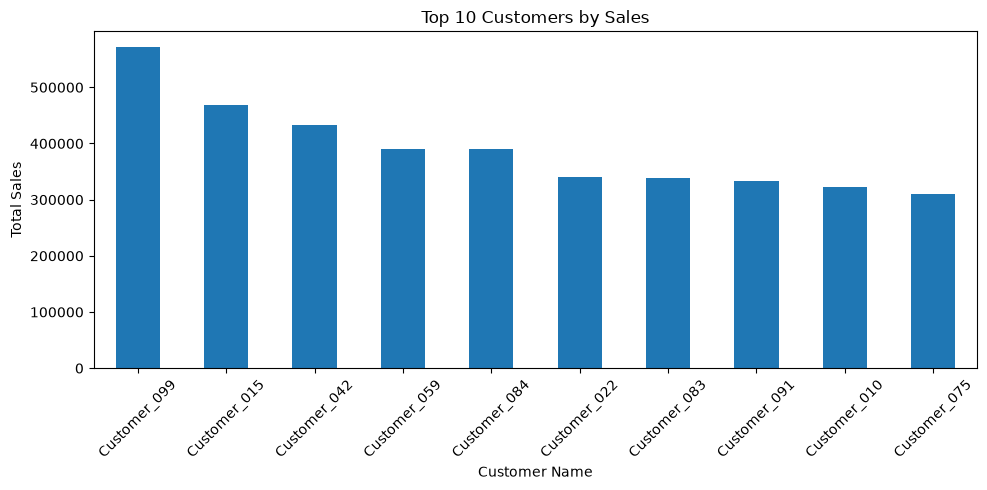

In [152]:
customer_sales.head(10).plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Customers by Sales"
)

plt.xlabel("Customer Name")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [153]:
status_count = df_clean["OrderStatus"].value_counts()

print("Order Status Count:")
print(status_count)

Order Status Count:
OrderStatus
Completed    310
Returned     108
Cancelled     82
Name: count, dtype: int64


In [154]:
status_sales = df_clean.groupby("OrderStatus")["Sales"].sum().sort_values(ascending=False)

print("Order Status-wise Sales:")
print(status_sales)

Order Status-wise Sales:
OrderStatus
Completed    7670166.15
Returned     3733455.79
Cancelled    2209407.96
Name: Sales, dtype: float64


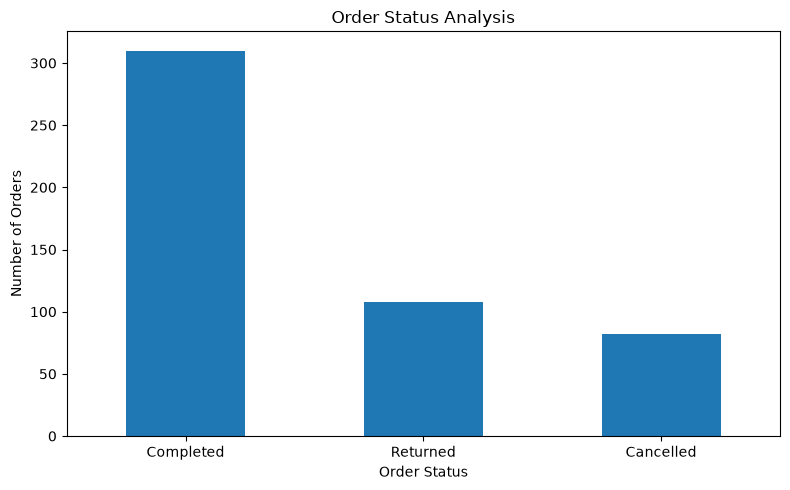

In [155]:
status_count.plot(
    kind="bar",
    figsize=(8, 5),
    title="Order Status Analysis"
)

plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [156]:
region_sales = (
    df_clean.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Region-wise Sales:")
print(region_sales)

Region-wise Sales:
Region
South    6269968.83
West     4774664.77
North    2568396.30
Name: Sales, dtype: float64


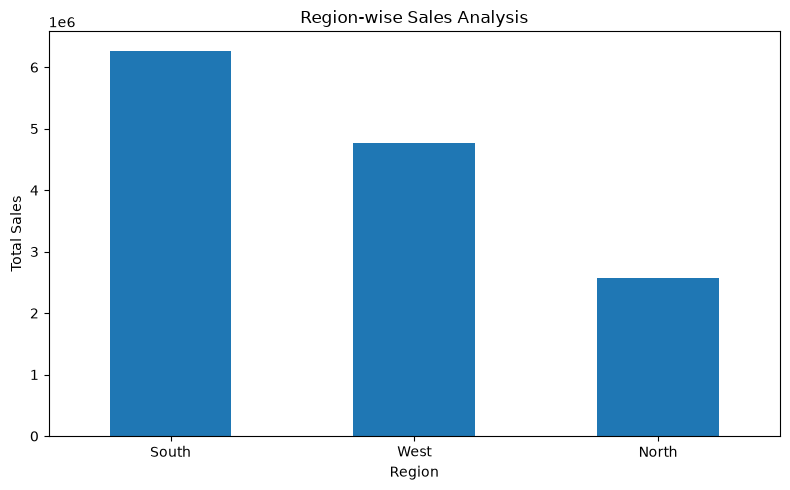

In [157]:
region_sales.plot(
    kind="bar",
    figsize=(8, 5),
    title="Region-wise Sales Analysis"
)

plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [158]:
region_percentage = (region_sales / region_sales.sum()) * 100

print("Region-wise Sales Contribution (%):")
print(region_percentage.round(2))

Region-wise Sales Contribution (%):
Region
South    46.06
West     35.07
North    18.87
Name: Sales, dtype: float64


In [159]:
monthly_sales = (
    df_clean.groupby(df_clean["OrderDate"].dt.to_period("M"))["Sales"]
    .sum()
    .sort_index()
)

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
OrderDate
2025-01    1128235.65
2025-02    1041647.27
2025-03    1602942.95
2025-04    1190597.40
2025-05    1243336.00
2025-06     896804.12
2025-07     873787.58
2025-08     687059.29
2025-09    1280092.88
2025-10    2074194.55
2025-11     907481.50
2025-12     686850.71
Freq: M, Name: Sales, dtype: float64


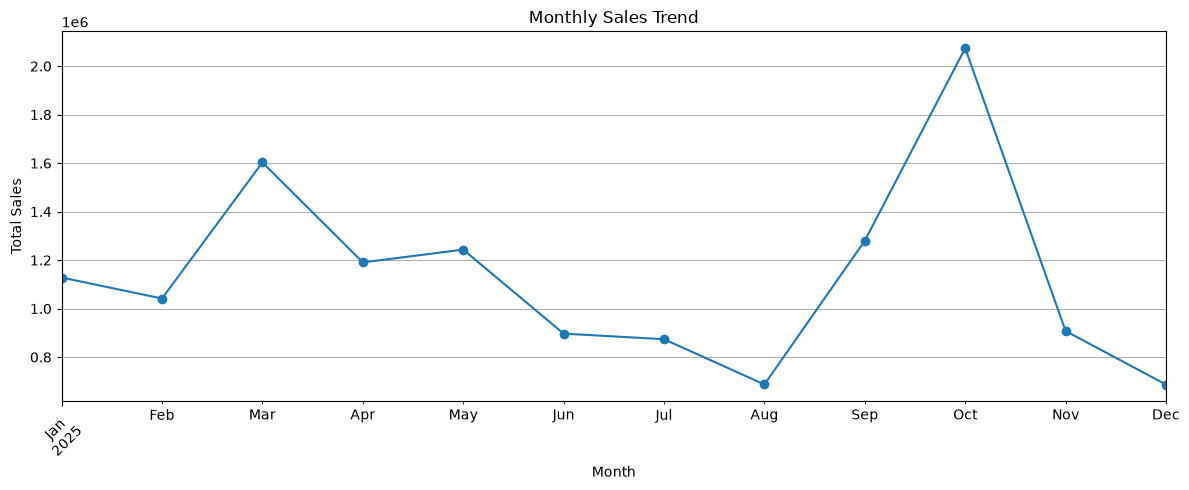

In [160]:
monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(12, 5),
    title="Monthly Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [161]:
print("Highest Sales Month:")
print(monthly_sales.idxmax(), monthly_sales.max())

print("Lowest Sales Month:")
print(monthly_sales.idxmin(), monthly_sales.min())

Highest Sales Month:
2025-10 2074194.55
Lowest Sales Month:
2025-12 686850.71


In [162]:
product_quantity = (
    df_clean.groupby("ProductName")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Products by Quantity:")
print(product_quantity.head(10))

Top 10 Products by Quantity:
ProductName
Pen Pack        177
Laptop          171
Backpack        154
Water Bottle    149
Headphones      145
Desk            139
Notebook        137
Smartphone      134
Office Chair    125
Mouse           124
Name: Quantity, dtype: int64


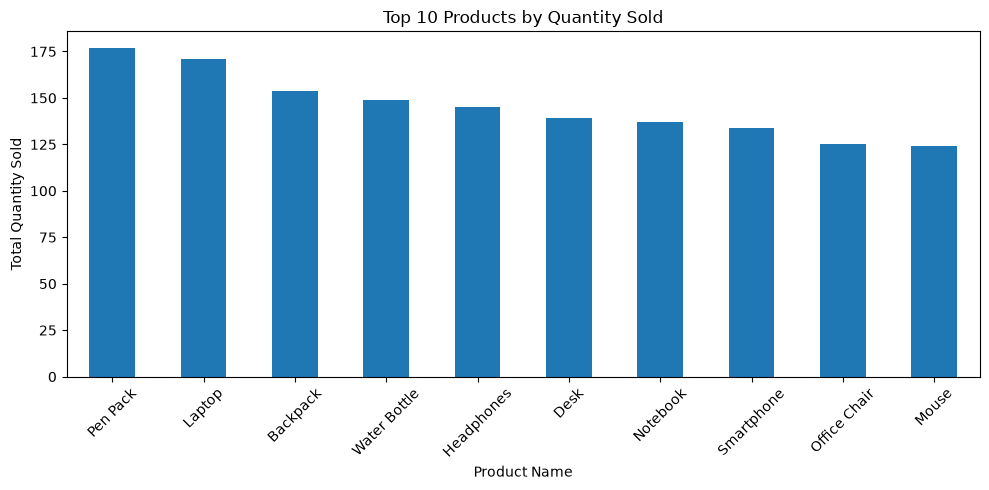

In [163]:
product_quantity.head(10).plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Products by Quantity Sold"
)

plt.xlabel("Product Name")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [164]:
print("========== BUSINESS INSIGHTS ==========")

print("\n1. Top Selling Product:")
print(df_clean.groupby("ProductName")["Sales"].sum().idxmax())

print("\n2. Highest Sales Category:")
print(df_clean.groupby("Category")["Sales"].sum().idxmax())

print("\n3. Highest Sales Region:")
print(df_clean.groupby("Region")["Sales"].sum().idxmax())

print("\n4. Most Used Payment Method:")
print(df_clean["PaymentMethod"].value_counts().idxmax())

print("\n5. Most Common Order Status:")
print(df_clean["OrderStatus"].value_counts().idxmax())

print("\n6. Highest Sales Month:")
print(monthly_sales.idxmax())

print("\n7. Total Sales:")
print(round(df_clean["Sales"].sum(), 2))

========== BUSINESS INSIGHTS ==========

1. Top Selling Product:
Laptop

2. Highest Sales Category:
Electronics

3. Highest Sales Region:
South

4. Most Used Payment Method:
UPI

5. Most Common Order Status:
Completed

6. Highest Sales Month:
2025-10

7. Total Sales:
13613029.9


In [165]:
recommendations = [
    "Focus on promoting top-selling products.",
    "Improve marketing strategies in low-performing regions.",
    "Analyze monthly sales trends to plan seasonal campaigns.",
    "Investigate returned and cancelled orders to reduce losses.",
    "Promote popular payment methods for customer convenience."
]

print("BUSINESS RECOMMENDATIONS")

for i, recommendation in enumerate(recommendations, start=1):
    print(f"{i}. {recommendation}")

BUSINESS RECOMMENDATIONS
1. Focus on promoting top-selling products.
2. Improve marketing strategies in low-performing regions.
3. Analyze monthly sales trends to plan seasonal campaigns.
4. Investigate returned and cancelled orders to reduce losses.
5. Promote popular payment methods for customer convenience.


# CodeAlpha Internship – Task 2
# Exploratory Data Analysis (EDA)

## 1. Project Objective
The objective of this project is to explore an e-commerce sales dataset, understand sales patterns, identify anomalies, and generate meaningful business insights.

## 2. Dataset Overview
- Initial records: 502
- Records after duplicate removal: 500
- Total columns: 14
- Missing values after cleaning: 0
- Duplicate records after cleaning: 0

## 3. Data Cleaning
The following operations were performed:
- Removed duplicate records.
- Handled missing City values using "Unknown".
- Filled missing DiscountPct values using the median.
- Standardized Category names.
- Validated numerical columns and dates.

## 4. Exploratory Data Analysis
The following analyses were performed:
- Product-wise sales analysis
- Category-wise sales analysis
- Region-wise sales analysis
- Monthly sales trend analysis
- Customer-wise sales analysis
- Payment method analysis
- Order status analysis
- Product quantity analysis
- Outlier detection
- Correlation analysis
- Hypothesis testing

## 5. Key Findings
- Total sales: 13,613,029.90
- Average sales: 27,226.06
- Total quantity: 1,455
- Top product by sales: Laptop
- Top category by sales: Electronics
- Potential outliers detected using IQR: 70
- Regional ANOVA p-value: 0.1841

## 6. Business Recommendations
- Promote top-performing products.
- Improve marketing strategies in low-performing regions.
- Use monthly sales trends for campaign planning.
- Investigate returned and cancelled orders.
- Understand customer payment preferences.

## 7. Conclusion
Exploratory Data Analysis helped identify sales trends, product performance, customer patterns, and data quality issues. The cleaned dataset is ready for further analysis and visualization.

## 8. Tools and Technologies
- Python
- Jupyter Notebook
- Pandas
- Matplotlib
- Seaborn
- SciPy

In [169]:
# CodeAlpha Internship – Task 3
# Data Visualization

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


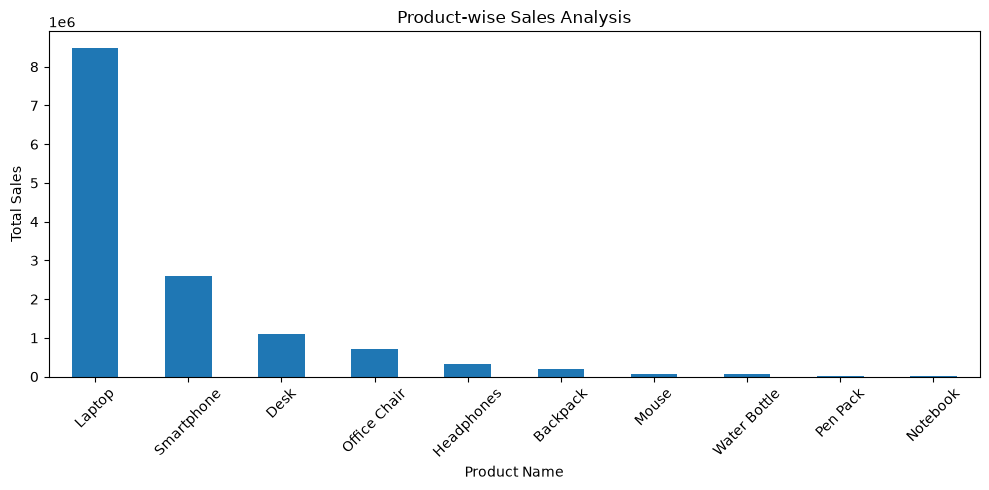

In [170]:
plt.figure(figsize=(10, 5))

product_sales.plot(kind="bar")

plt.title("Product-wise Sales Analysis")
plt.xlabel("Product Name")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [171]:
monthly_sales = (
    df_clean.groupby(df_clean["OrderDate"].dt.month)["Sales"]
    .sum()
    .sort_index()
)

print(monthly_sales)

OrderDate
1     1128235.65
2     1041647.27
3     1602942.95
4     1190597.40
5     1243336.00
6      896804.12
7      873787.58
8      687059.29
9     1280092.88
10    2074194.55
11     907481.50
12     686850.71
Name: Sales, dtype: float64


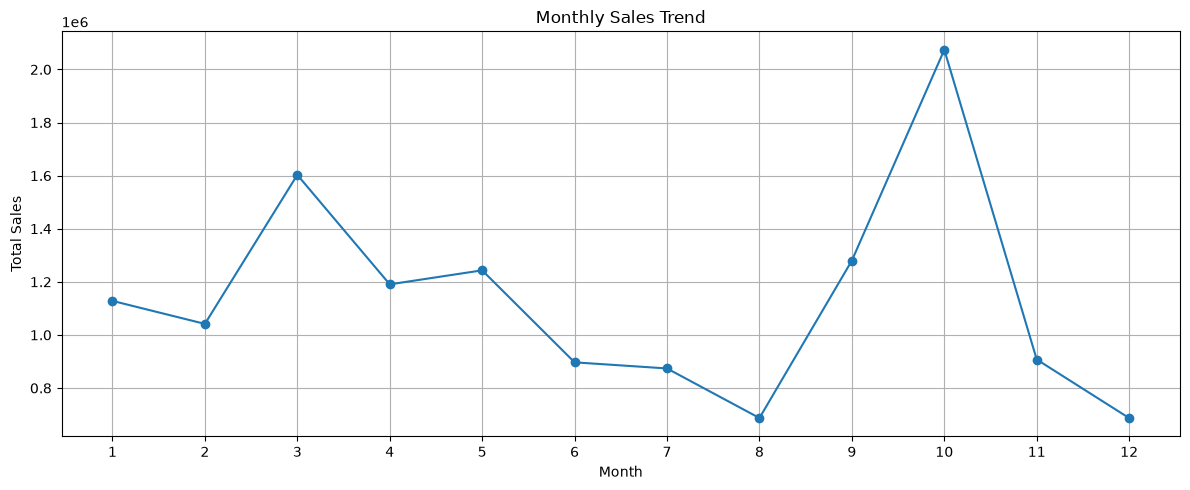

In [172]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

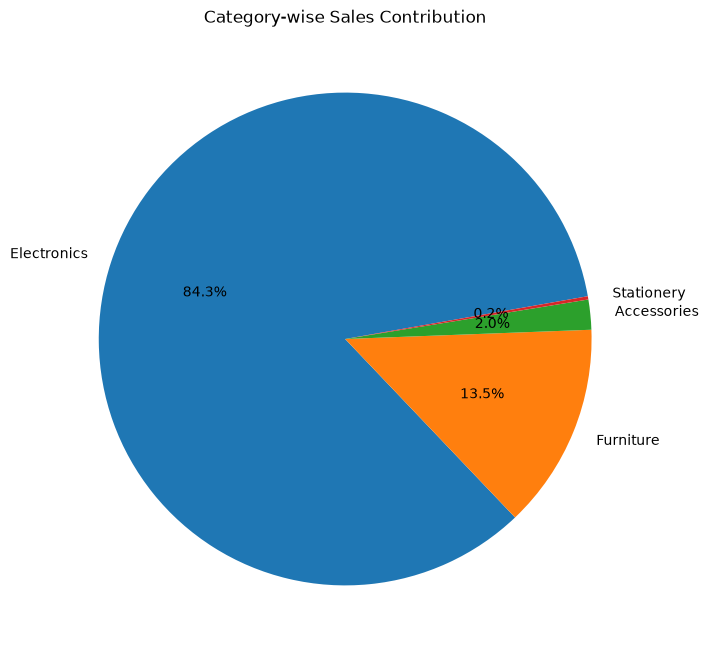

In [183]:
plt.figure(figsize=(8, 8))

plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=10
)

plt.title("Category-wise Sales Contribution")
plt.show()

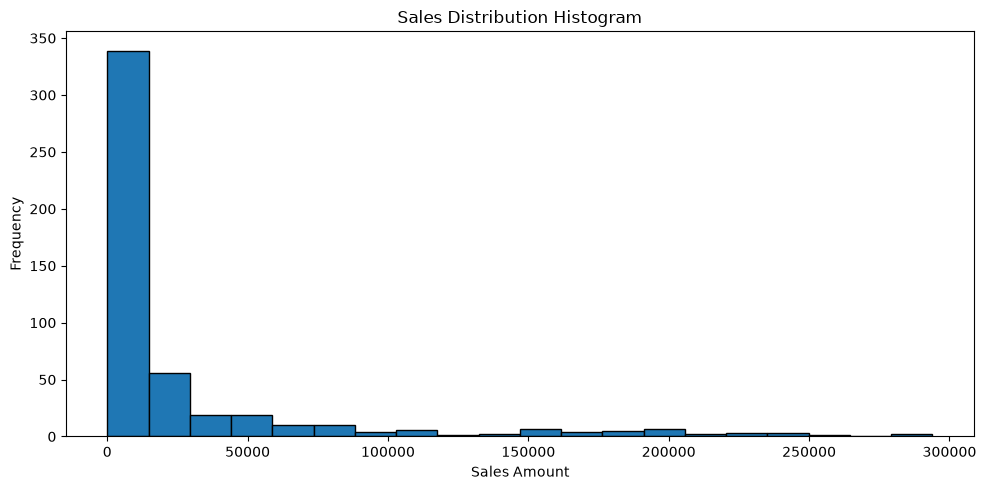

In [187]:
plt.figure(figsize=(10, 5))

plt.hist(df_clean["Sales"], bins=20, edgecolor="black")

plt.title("Sales Distribution Histogram")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

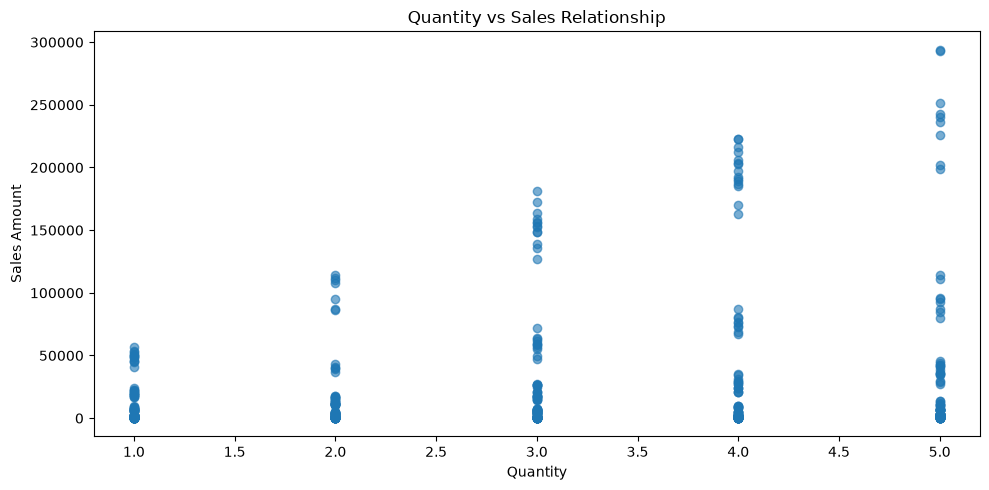

In [188]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df_clean["Quantity"],
    df_clean["Sales"],
    alpha=0.6
)

plt.title("Quantity vs Sales Relationship")
plt.xlabel("Quantity")
plt.ylabel("Sales Amount")

plt.tight_layout()
plt.show()

In [189]:
correlation = df_clean[
    ["Quantity", "UnitPrice", "DiscountPct", "Sales"]
].corr()

print(correlation)

             Quantity  UnitPrice  DiscountPct     Sales
Quantity     1.000000   0.004062    -0.003991  0.246631
UnitPrice    0.004062   1.000000    -0.054881  0.874928
DiscountPct -0.003991  -0.054881     1.000000 -0.085486
Sales        0.246631   0.874928    -0.085486  1.000000


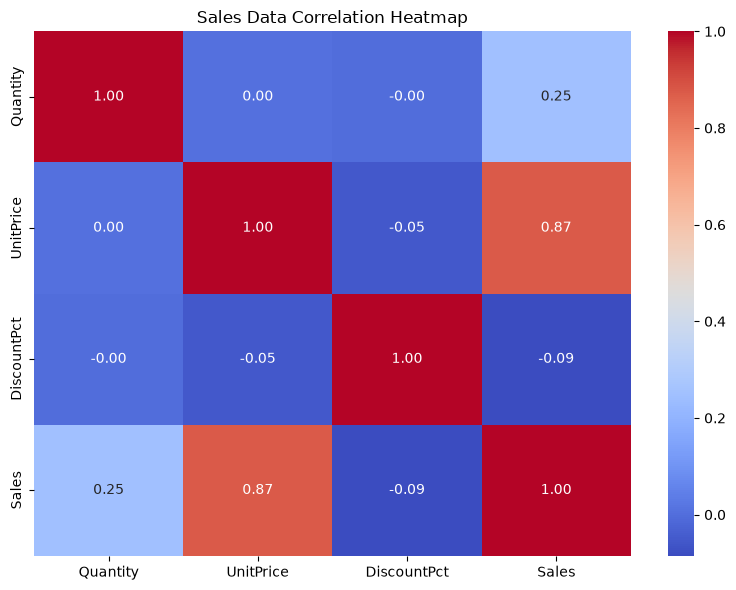

In [190]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Sales Data Correlation Heatmap")
plt.tight_layout()
plt.show()

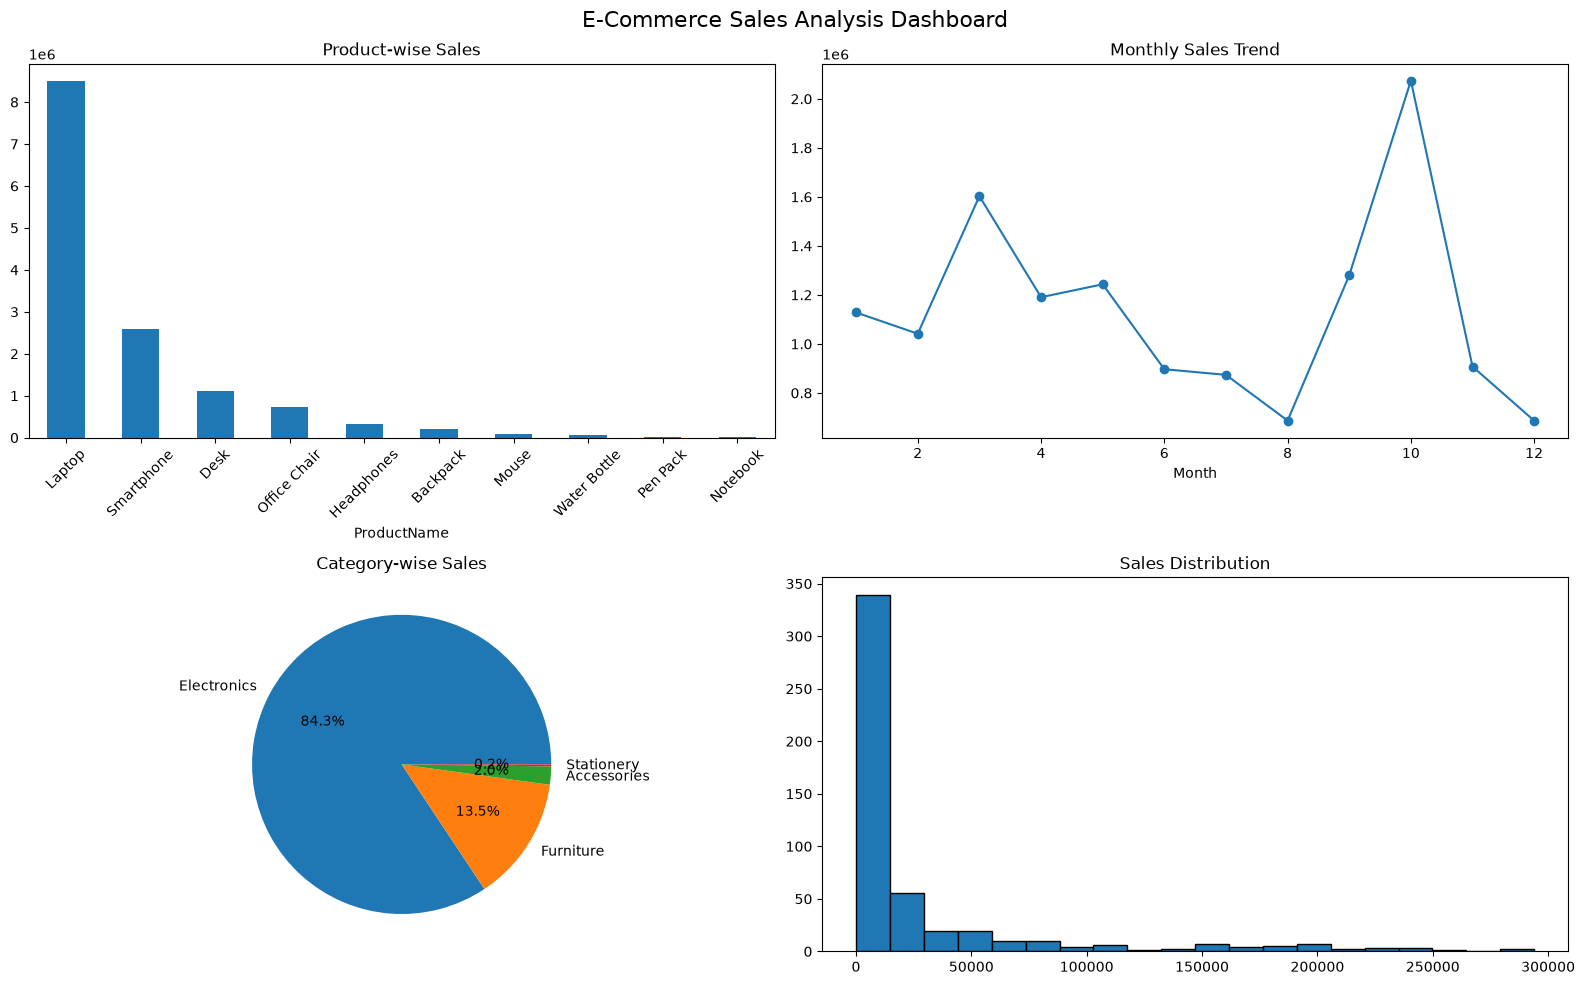

In [191]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Product-wise Sales
product_sales.plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Product-wise Sales")
axes[0, 0].tick_params(axis="x", rotation=45)

# 2. Monthly Sales Trend
axes[0, 1].plot(monthly_sales.index, monthly_sales.values, marker="o")
axes[0, 1].set_title("Monthly Sales Trend")
axes[0, 1].set_xlabel("Month")

# 3. Category-wise Sales
axes[1, 0].pie(
    category_sales,
    labels=category_sales.index,
    autopct="%1.1f%%"
)
axes[1, 0].set_title("Category-wise Sales")

# 4. Sales Distribution
axes[1, 1].hist(df_clean["Sales"], bins=20, edgecolor="black")
axes[1, 1].set_title("Sales Distribution")

plt.suptitle("E-Commerce Sales Analysis Dashboard", fontsize=16)
plt.tight_layout()
plt.show()

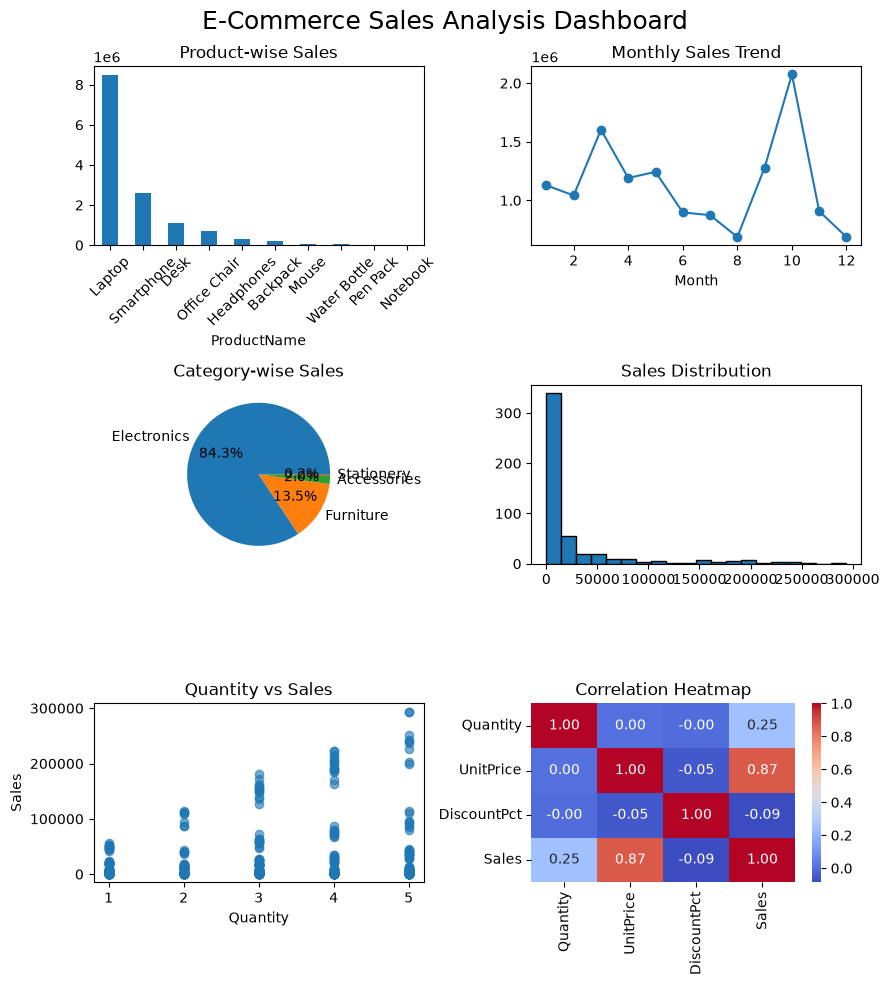

In [201]:
fig, axes = plt.subplots(3, 2, figsize=(9, 10))

# 1. Product-wise Sales
product_sales.plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Product-wise Sales")
axes[0, 0].tick_params(axis="x", rotation=45)

# 2. Monthly Sales Trend
axes[0, 1].plot(monthly_sales.index, monthly_sales.values, marker="o")
axes[0, 1].set_title("Monthly Sales Trend")
axes[0, 1].set_xlabel("Month")

# 3. Category-wise Sales
axes[1, 0].pie(category_sales, labels=category_sales.index,
               autopct="%1.1f%%")
axes[1, 0].set_title("Category-wise Sales")

# 4. Sales Distribution
axes[1, 1].hist(df_clean["Sales"], bins=20, edgecolor="black")
axes[1, 1].set_title("Sales Distribution")

# 5. Quantity vs Sales
axes[2, 0].scatter(df_clean["Quantity"], df_clean["Sales"], alpha=0.6)
axes[2, 0].set_title("Quantity vs Sales")
axes[2, 0].set_xlabel("Quantity")
axes[2, 0].set_ylabel("Sales")

# 6. Correlation Heatmap
sns.heatmap(correlation, annot=True, cmap="coolwarm",
            fmt=".2f", ax=axes[2, 1])
axes[2, 1].set_title("Correlation Heatmap")

plt.suptitle("E-Commerce Sales Analysis Dashboard", fontsize=18)
plt.tight_layout()
plt.show()

In [192]:
print("===== DATA VISUALIZATION INSIGHTS =====")

print("\n1. Highest Sales Product:")
print(product_sales.idxmax())

print("\n2. Lowest Sales Product:")
print(product_sales.idxmin())

print("\n3. Highest Sales Month:")
print(monthly_sales.idxmax())

print("\n4. Highest Sales Category:")
print(category_sales.idxmax())

print("\n5. Total Sales:")
print(round(df_clean["Sales"].sum(), 2))

print("\n6. Average Sales:")
print(round(df_clean["Sales"].mean(), 2))

===== DATA VISUALIZATION INSIGHTS =====

1. Highest Sales Product:
Laptop

2. Lowest Sales Product:
Notebook

3. Highest Sales Month:
10

4. Highest Sales Category:
Electronics

5. Total Sales:
13613029.9

6. Average Sales:
27226.06


# CodeAlpha Internship – Task 3
# Data Visualization

## 1. Project Objective
The objective of this task is to represent e-commerce sales data using different charts and visualizations to understand business performance and identify meaningful patterns.

## 2. Tools and Technologies
- Python
- Jupyter Notebook
- Pandas
- Matplotlib
- Seaborn

## 3. Visualizations Created

### 1. Bar Chart
Used to compare total sales across different products.

### 2. Line Chart
Used to analyze monthly sales trends.

### 3. Pie Chart
Used to display category-wise sales contribution.

### 4. Histogram
Used to understand the distribution of sales values.

### 5. Scatter Plot
Used to analyze the relationship between Quantity and Sales.

### 6. Correlation Heatmap
Used to visualize relationships between numerical columns.

### 7. Sales Dashboard
Combined multiple charts into one dashboard for a clear overview of sales performance.

## 4. Visualization Insights
The charts helped identify:
- Top and low-performing products.
- Monthly sales patterns.
- Category-wise sales contribution.
- Sales distribution.
- Relationships between numerical variables.

## 5. Conclusion
Data visualization helped transform raw e-commerce data into meaningful graphical insights. Different charts made it easier to compare sales performance, identify patterns, and understand business trends.

## 6. Final Tools
Python, Pandas, Matplotlib, Seaborn and Jupyter Notebook.